In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    PrecisionRecallDisplay
)

#### Objectif : Comprendre la structure du dataset

In [4]:
df = pd.read_csv('application_train.csv')
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
# Pourcentage de valeurs manquantes
(df.isna().mean() * 100).sort_values(ascending=False)

# Comptage des classes dans TARGET
target_counts = df['TARGET'].value_counts(normalize=True)
target_counts

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

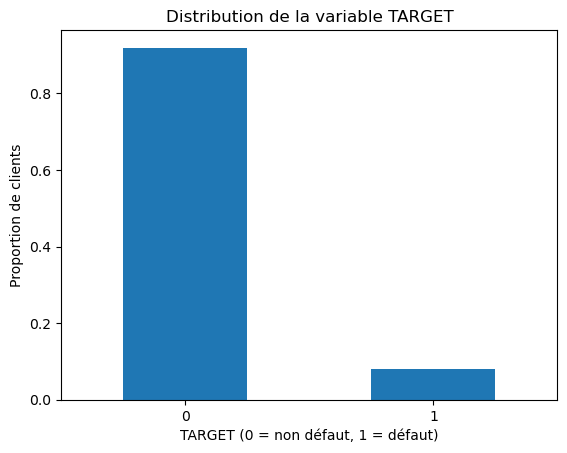

In [6]:
# Bar plot
target_counts.sort_index().plot(kind = 'bar')
plt.title('Distribution de la variable TARGET')
plt.xlabel('TARGET (0 = non défaut, 1 = défaut)')
plt.ylabel('Proportion de clients')
plt.xticks(rotation=0)
plt.show()

Les deux classes sont déséquilibrées (environ 8 % de défauts). Pour évaluer un modèle de scoring, on privilégiera notamment ROC-AUC et Average Precision, complétés par l'examen des erreurs de classification. L'accuracy seule est peu informative ici : prédire systématiquement la classe majoritaire donnerait un score élevé sans détecter de défauts. De plus, les coûts d'un refus injustifié et d'un défaut non anticipé ne sont pas nécessairement égaux.

#### Analyse et compréhension du risque

Différentes variables influes sur la définition du risque parmis lesquelles on retrouve : l'age, le revenu, ou encore le montant du crédit.

In [7]:
# Conversion pour étude d'âge des clients
df['AGE'] = (-df['DAYS_BIRTH'] / 365).round(1)
df['AGE'].describe()

count    307511.000000
mean         43.936992
std          11.956084
min          20.500000
25%          34.000000
50%          43.200000
75%          53.900000
max          69.100000
Name: AGE, dtype: float64

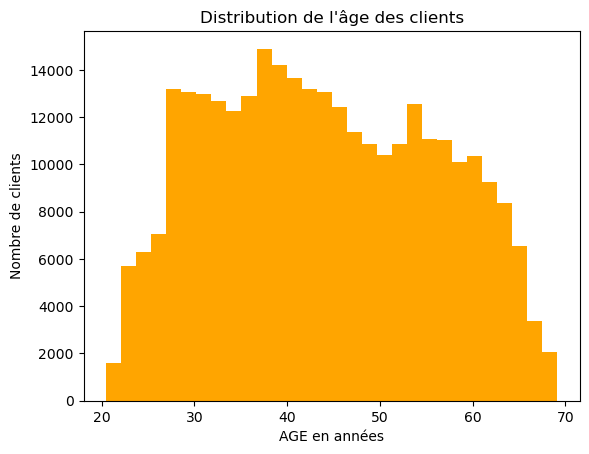

In [8]:
# Distribution de l'âge des clients
plt.hist(df['AGE'], bins = 30, color = 'orange')
plt.xlabel('AGE en années')
plt.ylabel('Nombre de clients')
plt.title("Distribution de l'âge des clients")
plt.show()

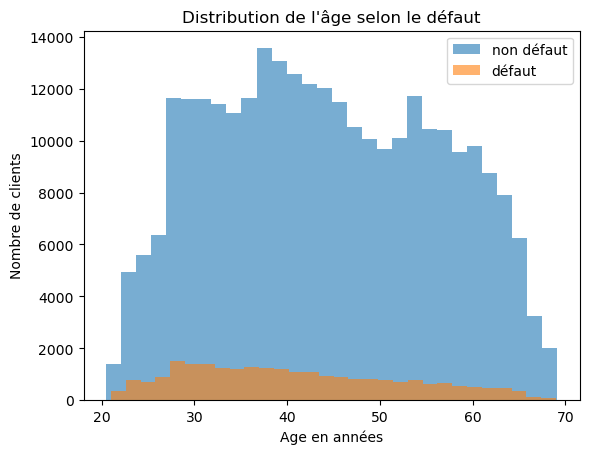

In [9]:
# Distribution de l'âge des clients selon le défaut
plt.hist(df[df['TARGET'] == 0]['AGE'], bins = 30, alpha = 0.6, label = 'non défaut')
plt.hist(df[df['TARGET'] == 1]['AGE'], bins = 30, alpha = 0.6, label = 'défaut')

plt.title("Distribution de l'âge selon le défaut")
plt.xlabel('Age en années')
plt.ylabel('Nombre de clients')
plt.legend()
plt.show()

Les défauts semblent davantage représentés chez les clients âgés de 25 à 40 ans. Toutefois, cette observation doit être interprétée avec prudence, car elle peut refléter une plus forte concentration de clients dans cette tranche d’âge. Aucun pic de risque net n’est observé, ce qui suggère que l’âge seul n’est pas un facteur discriminant suffisant.

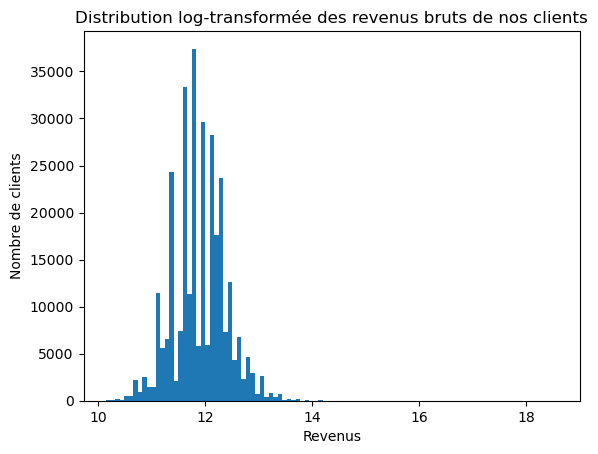

In [10]:
# Distribution des log-revenus des clients
plt.hist(np.log1p(df['AMT_INCOME_TOTAL']), bins = 100)
plt.title('Distribution log-transformée des revenus bruts de nos clients')
plt.xlabel('Revenus')
plt.ylabel('Nombre de clients')
plt.show()

La majorité des clients se situe dans une tranche de revenus intermédiaires, avec une dispersion modérée. Les très hauts revenus sont rares et constituent des cas particuliers à analyser séparément.

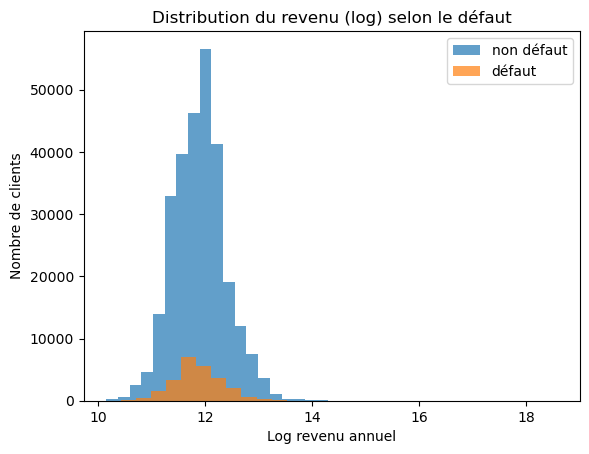

In [11]:
# Distribution des log-revenus des clients selon le défaut
df['LOG_INCOME'] = np.log1p(df['AMT_INCOME_TOTAL'])

plt.hist(df[df['TARGET'] == 0]['LOG_INCOME'], bins = 30, alpha = 0.7, label = 'non défaut')
plt.hist(df[df['TARGET'] == 1]['LOG_INCOME'], bins = 30, alpha = 0.7, label = 'défaut')
plt.title("Distribution du revenu (log) selon le défaut")
plt.xlabel('Log revenu annuel')
plt.ylabel('Nombre de clients')
plt.legend()
plt.show()

In [12]:
# Découpe du dataset en 5 tranches équivalentes basée sur la colonne AMT INCOME TOTAL
df['LOG_INCOME_BIN'] = pd.qcut(df['LOG_INCOME'], q=5)

C:\Users\Alexis\AppData\Local\Temp\ipykernel_16252\2901182040.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  defaut_rate_by_income = ( df.groupby('LOG_INCOME_BIN')['TARGET'].mean().reset_index() )


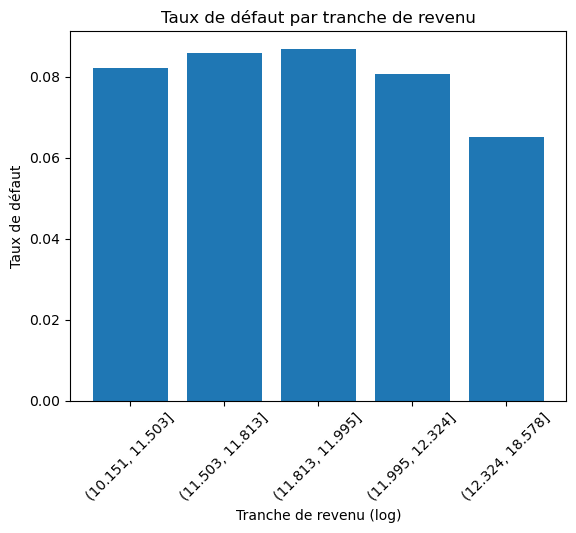

In [13]:
# Calcul du taux de défaut par tranche
defaut_rate_by_income = ( df.groupby('LOG_INCOME_BIN')['TARGET'].mean().reset_index() )

# Affichage du taux de défaut par tranche de revenu
plt.bar(
    defaut_rate_by_income['LOG_INCOME_BIN'].astype(str),
    defaut_rate_by_income['TARGET']
)

plt.title('Taux de défaut par tranche de revenu')
plt.xlabel('Tranche de revenu (log)')
plt.ylabel('Taux de défaut')
plt.xticks(rotation=45)
plt.show()

Le revenu, pris isolément, ne semble pas fortement discriminant pour expliquer le risque de défaut. En revanche, les clients appartenant à la tranche de revenus la plus élevée présentent un risque significativement plus faible.

### Indicateur supplémentaire : DTI_approx

In [14]:
# Il ne s'agit pas d'un DTI bancaire complet.
# Nous construisons ici un proxy annuité/revenu faute de connaître l'ensemble des dettes de chaque client

# Les revenus nuls ou négatifs sont considérés comme invalides
revenu_valide = df['AMT_INCOME_TOTAL'].where(
    df['AMT_INCOME_TOTAL'] > 0
)

# Calcul du ratio annuité / revenu
df['DTI_approx'] = df['AMT_ANNUITY'] / revenu_valide

# Vérification des résultats
print(df['DTI_approx'].describe())
print(
    "Valeurs manquantes :",
    df['DTI_approx'].isna().sum()
)

count    307499.000000
mean          0.180930
std           0.094574
min           0.000224
25%           0.114782
50%           0.162833
75%           0.229067
max           1.875965
Name: DTI_approx, dtype: float64
Valeurs manquantes : 12


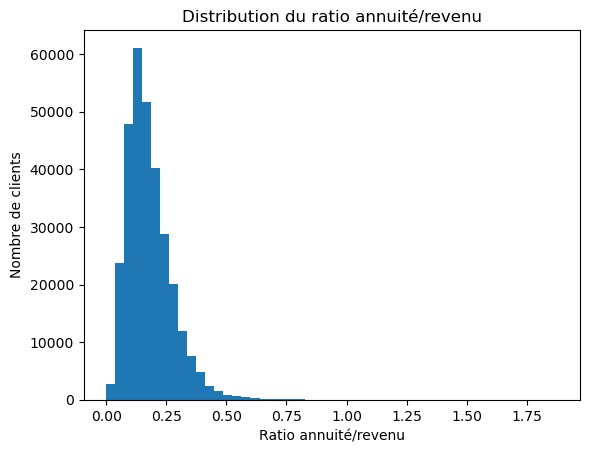

In [15]:
# Distribution du DTI_approx selon les clients
plt.hist(df['DTI_approx'], bins = 50)
plt.title("Distribution du ratio annuité/revenu")
plt.xlabel("Ratio annuité/revenu")
plt.ylabel("Nombre de clients")
plt.show()

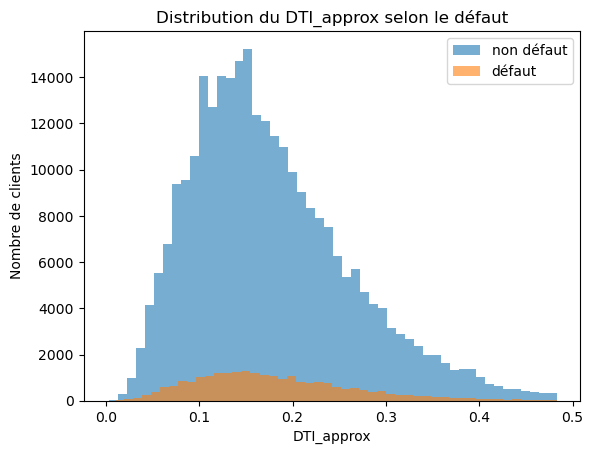

In [16]:
# Distribution du DTI_approx selon le défaut
dti_cap_eda = df['DTI_approx'].quantile(0.99) # Ici, le choix de ce quantile est uniquement utilisé pour une meilleure visibilité sur le plot.
df_dti = df.loc[df['DTI_approx'] <= dti_cap_eda].copy()

plt.hist(df_dti[df_dti['TARGET']==0]['DTI_approx'], bins = 50, alpha = 0.6, label = 'non défaut')
plt.hist(df_dti[df_dti['TARGET']==1]['DTI_approx'], bins = 50, alpha = 0.6, label = 'défaut')

plt.title('Distribution du DTI_approx selon le défaut')
plt.xlabel('DTI_approx')
plt.ylabel('Nombre de clients')
plt.legend()
plt.show()

In [17]:
# Découpage descriptif du DTI_approx en tranches
bins = [0, 0.13, 0.20, 0.30, np.inf]
labels = ["0-13%", "13-20%", "20-30%", "30%+"]
df_dti['DTI_BIN'] = pd.cut(df_dti['DTI_approx'], bins = bins, labels = labels)
default_rate_by_dti = (df_dti.groupby('DTI_BIN')['TARGET'].mean())

result = df_dti.groupby('DTI_BIN').agg(nb_clients = ('TARGET', 'count'), taux_defaut = ('TARGET', 'mean'))
result

C:\Users\Alexis\AppData\Local\Temp\ipykernel_16252\1013639322.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  default_rate_by_dti = (df_dti.groupby('DTI_BIN')['TARGET'].mean())
C:\Users\Alexis\AppData\Local\Temp\ipykernel_16252\1013639322.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  result = df_dti.groupby('DTI_BIN').agg(nb_clients = ('TARGET', 'count'), taux_defaut = ('TARGET', 'mean'))


,nb_clients,taux_defaut
DTI_BIN,,
0-13%,100449,0.073948
13-20%,101992,0.082144
20-30%,73742,0.087643
30%+,28241,0.082221


In [18]:
df_dti['AGE'] = -df_dti['DAYS_BIRTH'] / 365
age_bins = [18, 30, 40, 60, 100]
df_dti['AGE_BIN'] = pd.cut(df_dti['AGE'], bins = age_bins)
income_bins = [0, 50000, 100000, 200000, 750000]
df_dti['INCOME_BIN'] = pd.cut(df_dti['AMT_INCOME_TOTAL'], bins = income_bins)

C:\Users\Alexis\AppData\Local\Temp\ipykernel_16252\2727672123.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  result = df_dti.groupby(['DTI_BIN', 'AGE_BIN'])['TARGET'].mean().unstack()


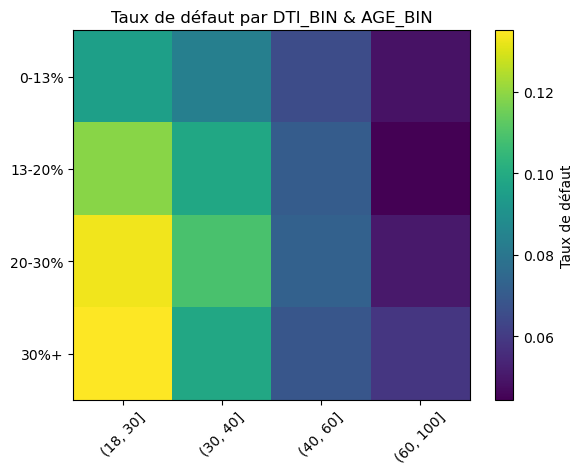

In [19]:
# Heatmap de l'âge et du DTI_approx en face du défaut
result = df_dti.groupby(['DTI_BIN', 'AGE_BIN'])['TARGET'].mean().unstack()
plt.imshow(result, aspect = 'auto')
plt.colorbar(label='Taux de défaut')
plt.xticks(range(len(result.columns)), result.columns, rotation = 45)
plt.yticks(range(len(result.index)), result.index)
plt.title('Taux de défaut par DTI_BIN & AGE_BIN')
plt.show()

#### Modélisation : Régression Logistique vs LightGBM

In [20]:
def construire_modele():
    """
    Construit une régression logistique avec :
    - Imputation des valeurs manquantes
    - Standardisation des variables
    - Régularisation L2
    """

    modele = Pipeline([
        ('imputation', SimpleImputer(strategy='median')),

        ('standardisation', StandardScaler()),

        ('regression_logistique', LogisticRegression(
            max_iter=1000,
            solver='lbfgs',
            random_state=42
        ))
    ])

    return modele

In [21]:
# =========================================================
# M0 - APPLICATION TRAIN : PRÉPARATION DES DONNÉES
# =========================================================

from sklearn.model_selection import train_test_split

# 1. Sélection des variables initiales
variables_application = [
    'AGE',
    'LOG_INCOME',
    'DTI_approx'
]

df_application = df[
    ['SK_ID_CURR', 'TARGET'] + variables_application
].copy()

# Vérification
assert df_application['SK_ID_CURR'].is_unique


# =========================================================
# 2. SÉPARATION TRAIN / VALIDATION / TEST
# =========================================================

identifiants = df_application['SK_ID_CURR'].to_numpy()
cibles = df_application['TARGET'].to_numpy()

# 80 % train + validation / 20 % test
ids_train_val, ids_test = train_test_split(
    identifiants,
    test_size=0.20,
    stratify=cibles,
    random_state=42
)

# Récupération des cibles par identifiant client
cible_par_client = df_application.set_index(
    'SK_ID_CURR'
)['TARGET']

# 60 % train / 20 % validation
ids_train, ids_validation = train_test_split(
    ids_train_val,
    test_size=0.25,
    stratify=cible_par_client.loc[ids_train_val].to_numpy(),
    random_state=42
)


# =========================================================
# 3. CONSTRUCTION DES ENSEMBLES
# =========================================================

mask_train = df_application['SK_ID_CURR'].isin(ids_train)

mask_val = df_application['SK_ID_CURR'].isin(ids_validation)

mask_test = df_application['SK_ID_CURR'].isin(ids_test)


# Variables explicatives
X_train_app = df_application.loc[
    mask_train, variables_application
]

X_val_app = df_application.loc[
    mask_val, variables_application
]


# Variable cible
y_train_app = df_application.loc[
    mask_train, 'TARGET'
]

y_val_app = df_application.loc[
    mask_val, 'TARGET'
]


# =========================================================
# 4. VÉRIFICATIONS
# =========================================================

assert mask_train.sum() == len(ids_train)
assert mask_val.sum() == len(ids_validation)
assert mask_test.sum() == len(ids_test)

assert not (mask_train & mask_val).any()
assert not (mask_train & mask_test).any()
assert not (mask_val & mask_test).any()

assert (
    mask_train.sum()
    + mask_val.sum()
    + mask_test.sum()
    == len(df_application)
)

print("=== RÉPARTITION DES DONNÉES ===")

print("Entraînement :", len(X_train_app))
print("Validation :", len(X_val_app))
print("Test :", len(ids_test))

print("\nNombre de variables :", len(variables_application))

print(
    "Prévalence TARGET=1 (train) :",
    round(y_train_app.mean(), 4)
)

=== RÉPARTITION DES DONNÉES ===
Entraînement : 184506
Validation : 61502
Test : 61503

Nombre de variables : 3
Prévalence TARGET=1 (train) : 0.0807


In [22]:
# Validation croisée stratifiée
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Métriques d'évaluation
scoring = {
    'ROC_AUC': 'roc_auc',
    'AP': 'average_precision'
}

# Hyperparamètres de la régression logistique
param_grid_lr = {
    'regression_logistique__C': [0.1, 1, 10],
    'regression_logistique__class_weight': [None, 'balanced']
}

# Recherche des meilleurs paramètres
grid_lr_app = GridSearchCV(
    estimator=construire_modele(),
    param_grid=param_grid_lr,
    scoring=scoring,
    refit='ROC_AUC',
    cv=cv,
    n_jobs=1
)

# Entraînement et validation croisée
grid_lr_app.fit(X_train_app, y_train_app)

# Meilleur modèle
modele_lr_app = grid_lr_app.best_estimator_

print("Meilleurs hyperparamètres :")
print(grid_lr_app.best_params_)

print(
    "ROC-AUC moyenne CV :",
    round(grid_lr_app.best_score_, 4)
)

Meilleurs hyperparamètres :
{'regression_logistique__C': 1, 'regression_logistique__class_weight': None}
ROC-AUC moyenne CV : 0.5894


In [23]:
# Modèle LightGBM initial
lgbm_app = lgb.LGBMClassifier(
    objective='binary',
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

# Espace de recherche
param_dist_lgbm = {
    'n_estimators': [150, 300, 500],
    'learning_rate': [0.03, 0.05],
    'num_leaves': [7, 15, 31],
    'min_child_samples': [100, 200],
    'reg_lambda': [0, 1, 5]
}

# Recherche aléatoire
random_lgbm_app = RandomizedSearchCV(
    estimator=lgbm_app,
    param_distributions=param_dist_lgbm,
    n_iter=10,
    scoring=scoring,
    refit='ROC_AUC',
    cv=cv,
    random_state=42,
    n_jobs=1
)

# Entraînement et validation croisée
random_lgbm_app.fit(X_train_app, y_train_app)

# Meilleur modèle
modele_lgbm_app = random_lgbm_app.best_estimator_

print("Meilleurs hyperparamètres :")
print(random_lgbm_app.best_params_)

print(
    "ROC-AUC moyenne CV :",
    round(random_lgbm_app.best_score_, 4)
)

Meilleurs hyperparamètres :
{'reg_lambda': 5, 'num_leaves': 7, 'n_estimators': 150, 'min_child_samples': 200, 'learning_rate': 0.05}
ROC-AUC moyenne CV : 0.5984


In [24]:
# Prédictions des probabilités
proba_lr_app = modele_lr_app.predict_proba(
    X_val_app
)[:, 1]

proba_lgbm_app = modele_lgbm_app.predict_proba(
    X_val_app
)[:, 1]


# Résultats de validation croisée du meilleur paramétrage
idx_lr = grid_lr_app.best_index_
idx_lgbm = random_lgbm_app.best_index_

# Tableau comparatif
comparaison_application = pd.DataFrame({
    'Modèle': [
        'Régression logistique',
        'LightGBM'
    ],

    'ROC-AUC validation': [
        roc_auc_score(y_val_app, proba_lr_app),
        roc_auc_score(y_val_app, proba_lgbm_app)
    ],
})

display(comparaison_application.round(4))

,Modèle,ROC-AUC validation
0,Régression logistique,0.5888
1,LightGBM,0.5975


In [25]:
# =========================================================
# M1 - ENRICHISSEMENT AVEC BUREAU
# =========================================================

bureau = pd.read_csv(
    "bureau.csv",
    usecols=[
        "SK_ID_CURR",
        "CREDIT_ACTIVE",
        "CREDIT_DAY_OVERDUE"
    ]
)

print("Dimensions initiales :", bureau.shape)


# Création d'indicateurs pour chaque crédit
bureau["IS_ACTIVE"] = (
    bureau["CREDIT_ACTIVE"] == "Active"
).astype(int)

bureau["IS_CLOSED"] = (
    bureau["CREDIT_ACTIVE"] == "Closed"
).astype(int)

bureau["IS_OVERDUE"] = (
    bureau["CREDIT_DAY_OVERDUE"] > 0
).astype(int)


# Agrégation des informations par client
bureau_features = (
    bureau.groupby("SK_ID_CURR")
    .agg(
        BUREAU_NB_CREDITS=("SK_ID_CURR", "size"),
        BUREAU_NB_ACTIVE=("IS_ACTIVE", "sum"),
        BUREAU_NB_CLOSED=("IS_CLOSED", "sum"),
        BUREAU_HAS_OVERDUE=("IS_OVERDUE", "max"),
        BUREAU_NB_OVERDUE_CREDITS=("IS_OVERDUE", "sum")
    )
    .reset_index()
)

print("Dimensions après agrégation :", bureau_features.shape)

display(bureau_features.head())

del bureau

Dimensions initiales : (1716428, 3)
Dimensions après agrégation : (305811, 6)


,SK_ID_CURR,BUREAU_NB_CREDITS,BUREAU_NB_ACTIVE,BUREAU_NB_CLOSED,BUREAU_HAS_OVERDUE,BUREAU_NB_OVERDUE_CREDITS
0,100001,7,3,4,0,0
1,100002,8,2,6,0,0
2,100003,4,1,3,0,0
3,100004,2,0,2,0,0
4,100005,3,2,1,0,0


In [26]:
# Jointure entre Application et Bureau
df_bureau = df_application.merge(
    bureau_features,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

# Indicateur de présence d'historique
# À créer AVANT le remplacement des NaN
df_bureau["HAS_BUREAU_HISTORY"] = (
    df_bureau["BUREAU_NB_CREDITS"].notna()
).astype(int)

# Remplacement des valeurs manquantes
bureau_cols = [
    "BUREAU_NB_CREDITS",
    "BUREAU_NB_ACTIVE",
    "BUREAU_NB_CLOSED",
    "BUREAU_HAS_OVERDUE",
    "BUREAU_NB_OVERDUE_CREDITS"
]

df_bureau[bureau_cols] = (
    df_bureau[bureau_cols].fillna(0)
)

# Variables utilisées pour M1
variables_bureau = (
    variables_application
    + bureau_cols
    + ["HAS_BUREAU_HISTORY"]
)

print("Nombre de variables :", len(variables_bureau))
print("Nombre de clients :", len(df_bureau))
assert len(variables_bureau) == 9
assert df_bureau["SK_ID_CURR"].is_unique
assert len(df_bureau) == len(df_application)

# Réutilisation des mêmes clients
mask_train_bureau = (
    df_bureau["SK_ID_CURR"].isin(ids_train)
)

mask_val_bureau = (
    df_bureau["SK_ID_CURR"].isin(ids_validation)
)

X_train_bureau = df_bureau.loc[
    mask_train_bureau, variables_bureau
]

X_val_bureau = df_bureau.loc[
    mask_val_bureau, variables_bureau
]

y_train_bureau = df_bureau.loc[
    mask_train_bureau, "TARGET"
]

y_val_bureau = df_bureau.loc[
    mask_val_bureau, "TARGET"
]

# Vérification de la comparabilité avec M0
assert len(X_train_bureau) == len(X_train_app)
assert len(X_val_bureau) == len(X_val_app)

assert np.array_equal(
    y_train_bureau.to_numpy(),
    y_train_app.to_numpy()
)

assert np.array_equal(
    y_val_bureau.to_numpy(),
    y_val_app.to_numpy()
)

print("Entraînement :", X_train_bureau.shape)
print("Validation :", X_val_bureau.shape)

Nombre de variables : 9
Nombre de clients : 307511
Entraînement : (184506, 9)
Validation : (61502, 9)


In [27]:
# =========================================================
# MODÉLISATION M1 : RÉGRESSION LOGISTIQUE VS LIGHTGBM
# =========================================================

# 1. Régression logistique
grid_lr_bureau = GridSearchCV(
    estimator=construire_modele(),
    param_grid=param_grid_lr,
    scoring=scoring,
    refit="ROC_AUC",
    cv=cv,
    n_jobs=1
)

grid_lr_bureau.fit(
    X_train_bureau,
    y_train_bureau
)

modele_lr_bureau = grid_lr_bureau.best_estimator_

# 2. LightGBM
random_lgbm_bureau = RandomizedSearchCV(
    estimator=lgbm_app,
    param_distributions=param_dist_lgbm,
    n_iter=10,
    scoring=scoring,
    refit="ROC_AUC",
    cv=cv,
    random_state=42,
    n_jobs=1
)

random_lgbm_bureau.fit(
    X_train_bureau,
    y_train_bureau
)

modele_lgbm_bureau = (
    random_lgbm_bureau.best_estimator_
)


# Résultats de la recherche
print("=== RÉGRESSION LOGISTIQUE ===")
print(grid_lr_bureau.best_params_)
print("ROC_AUC :", round(grid_lr_bureau.best_score_, 4))
print("\n=== LIGHTGBM ===")
print(random_lgbm_bureau.best_params_)
print("ROC_AUC :", round(random_lgbm_bureau.best_score_, 4))

=== RÉGRESSION LOGISTIQUE ===
{'regression_logistique__C': 10, 'regression_logistique__class_weight': 'balanced'}
ROC_AUC : 0.627

=== LIGHTGBM ===
{'reg_lambda': 0, 'num_leaves': 7, 'n_estimators': 500, 'min_child_samples': 200, 'learning_rate': 0.03}
ROC_AUC : 0.6354


In [28]:
# =========================================================
# M2 - ENRICHISSEMENT AVEC PREVIOUS APPLICATION
# =========================================================

# Chargement des colonnes nécessaires
previous = pd.read_csv(
    "previous_application.csv",
    usecols=[
        "SK_ID_CURR",
        "NAME_CONTRACT_STATUS",
        "AMT_APPLICATION",
        "DAYS_DECISION"
    ]
)

print("Dimensions initiales :", previous.shape)

# Conservation des décisions antérieures à la demande
previous = previous.loc[
    previous["DAYS_DECISION"] < 0
].copy()

# Identification des demandes refusées
previous["IS_REFUSED"] = (
    previous["NAME_CONTRACT_STATUS"] == "Refused"
).astype(int)

# Agrégation au niveau du client
prev_features = (
    previous.groupby("SK_ID_CURR")
    .agg(
        NB_PREV_APP=("SK_ID_CURR", "size"),
        NB_REFUSED=("IS_REFUSED", "sum"),
        AVG_AMT_APPLICATION=("AMT_APPLICATION", "mean")
    )
    .reset_index()
)

print("Dimensions après agrégation :", prev_features.shape)

display(prev_features.head())

# Libération de la mémoire
del previous

Dimensions initiales : (1670214, 4)
Dimensions après agrégation : (338857, 4)


,SK_ID_CURR,NB_PREV_APP,NB_REFUSED,AVG_AMT_APPLICATION
0,100001,1,0,24835.50
1,100002,1,0,179055.00
2,100003,3,0,435436.50
3,100004,1,0,24282.00
4,100005,2,0,22308.75


In [29]:
# Jointure avec notre dataset M1
df_previous = df_bureau.merge(
    prev_features,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

# Indicateur de présence d'un historique
# À calculer AVANT le remplacement des NaN
df_previous["HAS_PREV_HISTORY"] = (
    df_previous["NB_PREV_APP"].notna()
).astype(int)

# Absence d'historique : aucun événement comptabilisé
df_previous[
    ["NB_PREV_APP", "NB_REFUSED"]
] = df_previous[
    ["NB_PREV_APP", "NB_REFUSED"]
].fillna(0)

# AVG_AMT_APPLICATION reste NaN en l'absence
# de demande précédente : le pipeline LR
# réalisera l'imputation sur l'entraînement.

# Variables apportées par Previous Application
features_previous = [
    "NB_PREV_APP",
    "NB_REFUSED",
    "AVG_AMT_APPLICATION",
    "HAS_PREV_HISTORY"
]

# Liste cumulative des variables
variables_previous = (
    variables_bureau + features_previous
)

print("Nombre de variables :", len(variables_previous))

assert len(variables_previous) == 13
assert len(df_previous) == len(df_bureau)
assert df_previous["SK_ID_CURR"].is_unique

Nombre de variables : 13


In [30]:
# Réutilisation des mêmes identifiants clients
mask_train_previous = (
    df_previous["SK_ID_CURR"].isin(ids_train)
)

mask_val_previous = (
    df_previous["SK_ID_CURR"].isin(ids_validation)
)

# Variables explicatives
X_train_previous = df_previous.loc[
    mask_train_previous,
    variables_previous
]

X_val_previous = df_previous.loc[
    mask_val_previous,
    variables_previous
]

# Cible
y_train_previous = df_previous.loc[
    mask_train_previous,
    "TARGET"
]

y_val_previous = df_previous.loc[
    mask_val_previous,
    "TARGET"
]

# Vérification de la comparabilité avec M1
assert len(X_train_previous) == len(X_train_bureau)
assert len(X_val_previous) == len(X_val_bureau)

assert np.array_equal(
    df_previous.loc[mask_train_previous, "SK_ID_CURR"].to_numpy(),
    df_bureau.loc[mask_train_bureau, "SK_ID_CURR"].to_numpy()
)

assert np.array_equal(
    df_previous.loc[mask_val_previous, "SK_ID_CURR"].to_numpy(),
    df_bureau.loc[mask_val_bureau, "SK_ID_CURR"].to_numpy()
)

print("Entraînement :", X_train_previous.shape)
print("Validation :", X_val_previous.shape)

Entraînement : (184506, 13)
Validation : (61502, 13)


In [31]:
# =========================================================
# M2 - RÉGRESSION LOGISTIQUE
# =========================================================

grid_lr_previous = GridSearchCV(
    estimator=construire_modele(),
    param_grid=param_grid_lr,
    scoring=scoring,
    refit="ROC_AUC",
    cv=cv,
    n_jobs=1
)

# Entraînement
grid_lr_previous.fit(
    X_train_previous,
    y_train_previous
)

# Meilleur modèle
modele_lr_previous = grid_lr_previous.best_estimator_

print("=== RÉGRESSION LOGISTIQUE ===")

print("Meilleurs hyperparamètres :")
print(grid_lr_previous.best_params_)

print(
    "ROC-AUC moyenne CV :",
    round(grid_lr_previous.best_score_, 4)
)

=== RÉGRESSION LOGISTIQUE ===
Meilleurs hyperparamètres :
{'regression_logistique__C': 1, 'regression_logistique__class_weight': 'balanced'}
ROC-AUC moyenne CV : 0.642


In [32]:
# =========================================================
# M2 - LIGHTGBM
# =========================================================

random_lgbm_previous = RandomizedSearchCV(
    estimator=lgb.LGBMClassifier(
        objective="binary",
        random_state=42,
        n_jobs=4,
        verbosity=-1
    ),
    param_distributions=param_dist_lgbm,
    n_iter=10,
    scoring=scoring,
    refit="ROC_AUC",
    cv=cv,
    random_state=42,
    n_jobs=1
)

# Entraînement
random_lgbm_previous.fit(
    X_train_previous,
    y_train_previous
)

# Meilleur modèle
modele_lgbm_previous = (
    random_lgbm_previous.best_estimator_
)

print("=== LIGHTGBM ===")

print("Meilleurs hyperparamètres :")
print(random_lgbm_previous.best_params_)

print(
    "ROC-AUC moyenne CV :",
    round(random_lgbm_previous.best_score_, 4)
)

=== LIGHTGBM ===
Meilleurs hyperparamètres :
{'reg_lambda': 0, 'num_leaves': 7, 'n_estimators': 500, 'min_child_samples': 200, 'learning_rate': 0.03}
ROC-AUC moyenne CV : 0.6547


In [33]:
# =========================================================
# COMPARAISON PROGRESSIVE DES MODÈLES
# =========================================================

def resumer_modele(etape, nom_modele, recherche, X_val, y_val):

    # Vérification du critère de sélection
    assert recherche.refit == "ROC_AUC"

    # Probabilités prédites
    proba = recherche.best_estimator_.predict_proba(
        X_val
    )[:, 1]

    return {
        "Étape": etape,
        "Modèle": nom_modele,

        # ROC-AUC moyenne en validation croisée
        "ROC-AUC CV": recherche.best_score_,

        # ROC-AUC sur validation fixe
        "ROC-AUC validation": roc_auc_score(
            y_val, proba
        ),

        # Métrique secondaire
        "AP validation": average_precision_score(
            y_val, proba
        )
    }


comparaison_progressive = pd.DataFrame([

    # M0 : Application
    resumer_modele(
        "M0 - Application",
        "Régression logistique",
        grid_lr_app,
        X_val_app,
        y_val_app
    ),

    resumer_modele(
        "M0 - Application",
        "LightGBM",
        random_lgbm_app,
        X_val_app,
        y_val_app
    ),

    # M1 : Application + Bureau
    resumer_modele(
        "M1 - Bureau",
        "Régression logistique",
        grid_lr_bureau,
        X_val_bureau,
        y_val_bureau
    ),

    resumer_modele(
        "M1 - Bureau",
        "LightGBM",
        random_lgbm_bureau,
        X_val_bureau,
        y_val_bureau
    ),

    # M2 : Application + Bureau + Previous
    resumer_modele(
        "M2 - Previous",
        "Régression logistique",
        grid_lr_previous,
        X_val_previous,
        y_val_previous
    ),

    resumer_modele(
        "M2 - Previous",
        "LightGBM",
        random_lgbm_previous,
        X_val_previous,
        y_val_previous
    )
])

display(comparaison_progressive.round(4))

,Étape,Modèle,ROC-AUC CV,ROC-AUC validation,AP validation
0,M0 - Application,Régression logistique,0.5894,0.5888,0.1088
1,M0 - Application,LightGBM,0.5984,0.5975,0.1116
2,M1 - Bureau,Régression logistique,0.6270,0.6185,0.1235
3,M1 - Bureau,LightGBM,0.6354,0.6290,0.1288
4,M2 - Previous,Régression logistique,0.6420,0.6391,0.1351
5,M2 - Previous,LightGBM,0.6547,0.6503,0.1429


In [34]:
# Comparaison du gain de ROC-AUC sur validation
table_auc = comparaison_progressive.pivot(
    index="Modèle",
    columns="Étape",
    values="ROC-AUC validation"
)

gain_previous = (
    table_auc["M2 - Previous"]
    - table_auc["M1 - Bureau"]
)

print("Gain de ROC-AUC apporté par Previous Application :")

display(
    gain_previous.to_frame(
        name="Gain ROC-AUC"
    ).round(4)
)

Gain de ROC-AUC apporté par Previous Application :


,Gain ROC-AUC
Modèle,
LightGBM,0.0213
Régression logistique,0.0206


In [35]:
# =========================================================
# M3 - ENRICHISSEMENT AVEC INSTALLMENTS PAYMENTS
# =========================================================

colonnes_install = [
    "SK_ID_CURR",
    "DAYS_ENTRY_PAYMENT",
    "DAYS_INSTALMENT"
]

# Agrégation progressive pour éviter de charger
# les 13,6 millions de lignes en mémoire simultanément.
install_aggr = None

nb_lignes_lues = 0
nb_lignes_conservees = 0

for chunk in pd.read_csv(
    "installments_payments.csv",
    usecols=colonnes_install,
    dtype={
        "SK_ID_CURR": "int32",
        "DAYS_ENTRY_PAYMENT": "float32",
        "DAYS_INSTALMENT": "float32"
    },
    chunksize=500_000
):

    nb_lignes_lues += len(chunk)

    # On conserve uniquement les paiements observés
    chunk = chunk.dropna(
        subset=["DAYS_ENTRY_PAYMENT", "DAYS_INSTALMENT"]
    ).copy()

    # Contrôle temporel : dates antérieures à la demande
    chunk = chunk.loc[
        (chunk["DAYS_ENTRY_PAYMENT"] < 0) &
        (chunk["DAYS_INSTALMENT"] < 0)
    ].copy()

    nb_lignes_conservees += len(chunk)

    if chunk.empty:
        continue

    # Calcul du retard
    chunk["DELAY"] = (
        chunk["DAYS_ENTRY_PAYMENT"]
        - chunk["DAYS_INSTALMENT"]
    )

    chunk["LATE"] = (
        chunk["DELAY"] > 0
    ).astype("int8")

    chunk["POSITIVE_DELAY"] = (
        chunk["DELAY"].clip(lower=0)
    )

    # Agrégation pour chaque morceau
    agg = chunk.groupby("SK_ID_CURR").agg(
        N_PAYMENTS=("LATE", "size"),
        NB_LATE_PAYMENTS=("LATE", "sum"),
        SUM_DELAY=("POSITIVE_DELAY", "sum")
    )

    # Cumul des agrégations
    if install_aggr is None:
        install_aggr = agg
    else:
        install_aggr = install_aggr.add(
            agg,
            fill_value=0
        )

print("Lignes lues :", nb_lignes_lues)
print("Paiements conservés :", nb_lignes_conservees)

assert install_aggr is not None

# Construction des indicateurs finaux
install_aggr["AVG_DELAY"] = (
    install_aggr["SUM_DELAY"]
    / install_aggr["N_PAYMENTS"]
)

install_aggr["LATE_PAYMENT_RATIO"] = (
    install_aggr["NB_LATE_PAYMENTS"]
    / install_aggr["N_PAYMENTS"]
)

install_features = install_aggr[
    [
        "NB_LATE_PAYMENTS",
        "AVG_DELAY",
        "LATE_PAYMENT_RATIO"
    ]
].reset_index()

display(install_features.head())

Lignes lues : 13605401
Paiements conservés : 13602496


,SK_ID_CURR,NB_LATE_PAYMENTS,AVG_DELAY,LATE_PAYMENT_RATIO
0,100001,1.0,1.571429,0.142857
1,100002,0.0,0.000000,0.000000
2,100003,0.0,0.000000,0.000000
3,100004,0.0,0.000000,0.000000
4,100005,1.0,0.111111,0.111111


In [36]:
# =========================================================
# M3 - JOINTURE ET PRÉPARATION DES DONNÉES
# =========================================================

df_installments = df_previous.merge(
    install_features,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

# Présence d'un historique de paiements observés
# IMPORTANT : à calculer avant le fillna
df_installments["HAS_INSTALL_HISTORY"] = (
    df_installments["NB_LATE_PAYMENTS"].notna()
).astype(int)

# Absence d'historique :
# aucun paiement tardif observé
df_installments[
    ["NB_LATE_PAYMENTS", "LATE_PAYMENT_RATIO"]
] = df_installments[
    ["NB_LATE_PAYMENTS", "LATE_PAYMENT_RATIO"]
].fillna(0)

# AVG_DELAY reste NaN sans historique :
# son imputation sera effectuée par le pipeline LR.

# Quatre variables supplémentaires
features_installments = [
    "NB_LATE_PAYMENTS",
    "AVG_DELAY",
    "LATE_PAYMENT_RATIO",
    "HAS_INSTALL_HISTORY"
]

# Variables cumulatives
variables_installments = (
    variables_previous + features_installments
)

print("Nombre de variables :", len(variables_installments))
print("Nombre de clients :", len(df_installments))

assert len(variables_installments) == 17
assert len(df_installments) == len(df_previous)
assert df_installments["SK_ID_CURR"].is_unique

Nombre de variables : 17
Nombre de clients : 307511


In [37]:
# Réutilisation des mêmes clients
mask_train_install = (
    df_installments["SK_ID_CURR"].isin(ids_train)
)

mask_val_install = (
    df_installments["SK_ID_CURR"].isin(ids_validation)
)

# Variables explicatives
X_train_install = df_installments.loc[
    mask_train_install,
    variables_installments
]

X_val_install = df_installments.loc[
    mask_val_install,
    variables_installments
]

# Cible
y_train_install = df_installments.loc[
    mask_train_install,
    "TARGET"
]

y_val_install = df_installments.loc[
    mask_val_install,
    "TARGET"
]

# Vérification : mêmes clients que M2, dans le même ordre
assert np.array_equal(
    df_installments.loc[
        mask_train_install, "SK_ID_CURR"
    ].to_numpy(),
    df_previous.loc[
        mask_train_previous, "SK_ID_CURR"
    ].to_numpy()
)

assert np.array_equal(
    df_installments.loc[
        mask_val_install, "SK_ID_CURR"
    ].to_numpy(),
    df_previous.loc[
        mask_val_previous, "SK_ID_CURR"
    ].to_numpy()
)

print("Entraînement :", X_train_install.shape)
print("Validation :", X_val_install.shape)

Entraînement : (184506, 17)
Validation : (61502, 17)


In [38]:
# =========================================================
# M3 - RÉGRESSION LOGISTIQUE
# =========================================================

grid_lr_install = GridSearchCV(
    estimator=construire_modele(),
    param_grid=param_grid_lr,
    scoring=scoring,
    refit="ROC_AUC",
    cv=cv,
    n_jobs=1
)

grid_lr_install.fit(
    X_train_install,
    y_train_install
)

modele_lr_install = grid_lr_install.best_estimator_

print("=== RÉGRESSION LOGISTIQUE ===")

print("Meilleurs hyperparamètres :")
print(grid_lr_install.best_params_)

print(
    "ROC-AUC moyenne CV :",
    round(grid_lr_install.best_score_, 4)
)

=== RÉGRESSION LOGISTIQUE ===
Meilleurs hyperparamètres :
{'regression_logistique__C': 1, 'regression_logistique__class_weight': 'balanced'}
ROC-AUC moyenne CV : 0.6543


In [39]:
# =========================================================
# M3 - LIGHTGBM
# =========================================================

random_lgbm_install = RandomizedSearchCV(
    estimator=lgb.LGBMClassifier(
        objective="binary",
        random_state=42,
        n_jobs=4,
        verbosity=-1
    ),
    param_distributions=param_dist_lgbm,
    n_iter=10,
    scoring=scoring,
    refit="ROC_AUC",
    cv=cv,
    random_state=42,
    n_jobs=1
)

random_lgbm_install.fit(
    X_train_install,
    y_train_install
)

modele_lgbm_install = (
    random_lgbm_install.best_estimator_
)

print("=== LIGHTGBM ===")

print("Meilleurs hyperparamètres :")
print(random_lgbm_install.best_params_)

print(
    "ROC-AUC moyenne CV :",
    round(random_lgbm_install.best_score_, 4)
)

=== LIGHTGBM ===
Meilleurs hyperparamètres :
{'reg_lambda': 5, 'num_leaves': 15, 'n_estimators': 300, 'min_child_samples': 200, 'learning_rate': 0.05}
ROC-AUC moyenne CV : 0.6674


In [40]:
# =========================================================
# M4 - ENRICHISSEMENT AVEC EXT_SOURCE
# =========================================================

# Chargement des trois scores externes
ext = pd.read_csv(
    "application_train.csv",
    usecols=[
        "SK_ID_CURR",
        "EXT_SOURCE_1",
        "EXT_SOURCE_2",
        "EXT_SOURCE_3"
    ]
)

# Vérification de l'unicité des clients
assert ext["SK_ID_CURR"].is_unique

# Jointure avec les données M3
df_ext = df_installments.merge(
    ext,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

# Conservation de tous les clients
assert len(df_ext) == len(df_installments)
assert df_ext["SK_ID_CURR"].is_unique

# Nouvelles variables
features_ext = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

# Ensemble des 20 variables
variables_ext = (
    variables_installments + features_ext
)

assert len(variables_ext) == 20
assert len(set(variables_ext)) == 20

print("Nombre de clients :", len(df_ext))
print("Nombre de variables :", len(variables_ext))

# Proportion de valeurs manquantes
print("\nValeurs manquantes des scores externes :")

display(
    df_ext[features_ext]
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .to_frame("Valeurs manquantes (%)")
)

Nombre de clients : 307511
Nombre de variables : 20

Valeurs manquantes des scores externes :


,Valeurs manquantes (%)
EXT_SOURCE_1,56.38
EXT_SOURCE_2,0.21
EXT_SOURCE_3,19.83


In [41]:
# =========================================================
# PRÉPARATION DES DONNÉES M4
# =========================================================

# Réutilisation des identifiants initiaux
mask_train_ext = df_ext["SK_ID_CURR"].isin(ids_train)

mask_val_ext = df_ext["SK_ID_CURR"].isin(ids_validation)


# Variables explicatives
X_train_ext = df_ext.loc[
    mask_train_ext,
    variables_ext
]

X_val_ext = df_ext.loc[
    mask_val_ext,
    variables_ext
]


# Variable cible
y_train_ext = df_ext.loc[
    mask_train_ext,
    "TARGET"
]

y_val_ext = df_ext.loc[
    mask_val_ext,
    "TARGET"
]


# Vérifications
assert np.array_equal(
    df_ext.loc[mask_train_ext, "SK_ID_CURR"].to_numpy(),
    df_installments.loc[
        mask_train_install, "SK_ID_CURR"
    ].to_numpy()
)

assert np.array_equal(
    df_ext.loc[mask_val_ext, "SK_ID_CURR"].to_numpy(),
    df_installments.loc[
        mask_val_install, "SK_ID_CURR"
    ].to_numpy()
)

assert np.array_equal(
    y_train_ext.to_numpy(),
    y_train_install.to_numpy()
)

assert np.array_equal(
    y_val_ext.to_numpy(),
    y_val_install.to_numpy()
)

print("Entraînement :", X_train_ext.shape)
print("Validation :", X_val_ext.shape)

print(
    "Prévalence TARGET=1 :",
    round(y_train_ext.mean(), 4)
)

Entraînement : (184506, 20)
Validation : (61502, 20)
Prévalence TARGET=1 : 0.0807


In [42]:
# =========================================================
# M4 - RÉGRESSION LOGISTIQUE
# =========================================================

grid_lr_ext = GridSearchCV(
    estimator=construire_modele(),

    param_grid=param_grid_lr,

    scoring=scoring,

    refit="ROC_AUC",

    cv=cv,

    n_jobs=1
)

# Entraînement
grid_lr_ext.fit(
    X_train_ext,
    y_train_ext
)

# Meilleur modèle
modele_lr_ext = grid_lr_ext.best_estimator_

print("=== RÉGRESSION LOGISTIQUE ===")

print("\nMeilleurs hyperparamètres :")
print(grid_lr_ext.best_params_)

print(
    "\nROC-AUC moyenne CV :",
    round(grid_lr_ext.best_score_, 4)
)

=== RÉGRESSION LOGISTIQUE ===

Meilleurs hyperparamètres :
{'regression_logistique__C': 0.1, 'regression_logistique__class_weight': 'balanced'}

ROC-AUC moyenne CV : 0.7337


In [43]:
# =========================================================
# M4 - LIGHTGBM
# =========================================================

random_lgbm_ext = RandomizedSearchCV(

    estimator=lgb.LGBMClassifier(
        objective="binary",
        random_state=42,
        n_jobs=4,
        verbosity=-1
    ),

    param_distributions=param_dist_lgbm,

    n_iter=10,

    scoring=scoring,

    refit="ROC_AUC",

    cv=cv,

    random_state=42,

    n_jobs=1
)

# Entraînement
random_lgbm_ext.fit(
    X_train_ext,
    y_train_ext
)

# Meilleur modèle
modele_lgbm_ext = (
    random_lgbm_ext.best_estimator_
)

print("=== LIGHTGBM ===")

print("\nMeilleurs hyperparamètres :")
print(random_lgbm_ext.best_params_)

print(
    "\nROC-AUC moyenne CV :",
    round(random_lgbm_ext.best_score_, 4)
)

=== LIGHTGBM ===

Meilleurs hyperparamètres :
{'reg_lambda': 5, 'num_leaves': 15, 'n_estimators': 300, 'min_child_samples': 200, 'learning_rate': 0.05}

ROC-AUC moyenne CV : 0.7446


In [44]:
# =========================================================
# COMPARAISON FINALE : M0 À M4
# =========================================================

experiences = [
    (
        "M0 - Application",
        grid_lr_app,
        random_lgbm_app,
        X_val_app,
        y_val_app
    ),
    (
        "M1 - Bureau",
        grid_lr_bureau,
        random_lgbm_bureau,
        X_val_bureau,
        y_val_bureau
    ),
    (
        "M2 - Previous",
        grid_lr_previous,
        random_lgbm_previous,
        X_val_previous,
        y_val_previous
    ),
    (
        "M3 - Installments",
        grid_lr_install,
        random_lgbm_install,
        X_val_install,
        y_val_install
    ),
    (
        "M4 - EXT_SOURCE",
        grid_lr_ext,
        random_lgbm_ext,
        X_val_ext,
        y_val_ext
    )
]

resultats = []

for etape, lr, lgbm, X_val, y_val in experiences:

    for nom_modele, recherche in [
        ("Régression logistique", lr),
        ("LightGBM", lgbm)
    ]:

        # Vérification de la métrique d'optimisation
        assert recherche.refit == "ROC_AUC"

        # Prédictions
        proba = recherche.best_estimator_.predict_proba(
            X_val
        )[:, 1]

        resultats.append({
            "Étape": etape,
            "Modèle": nom_modele,
            "ROC-AUC CV": recherche.best_score_,
            "ROC-AUC validation": roc_auc_score(
                y_val, proba
            ),
            "AP validation": average_precision_score(
                y_val, proba
            )
        })

# Tableau complet
comparaison_progressive = pd.DataFrame(resultats)

display(comparaison_progressive.round(4))

,Étape,Modèle,ROC-AUC CV,ROC-AUC validation,AP validation
0,M0 - Application,Régression logistique,0.5894,0.5888,0.1088
1,M0 - Application,LightGBM,0.5984,0.5975,0.1116
2,M1 - Bureau,Régression logistique,0.6270,0.6185,0.1235
3,M1 - Bureau,LightGBM,0.6354,0.6290,0.1288
4,M2 - Previous,Régression logistique,0.6420,0.6391,0.1351
5,M2 - Previous,LightGBM,0.6547,0.6503,0.1429
6,M3 - Installments,Régression logistique,0.6543,0.6518,0.1428
7,M3 - Installments,LightGBM,0.6674,0.6638,0.1529
8,M4 - EXT_SOURCE,Régression logistique,0.7337,0.7338,0.2083
9,M4 - EXT_SOURCE,LightGBM,0.7446,0.7443,0.2257


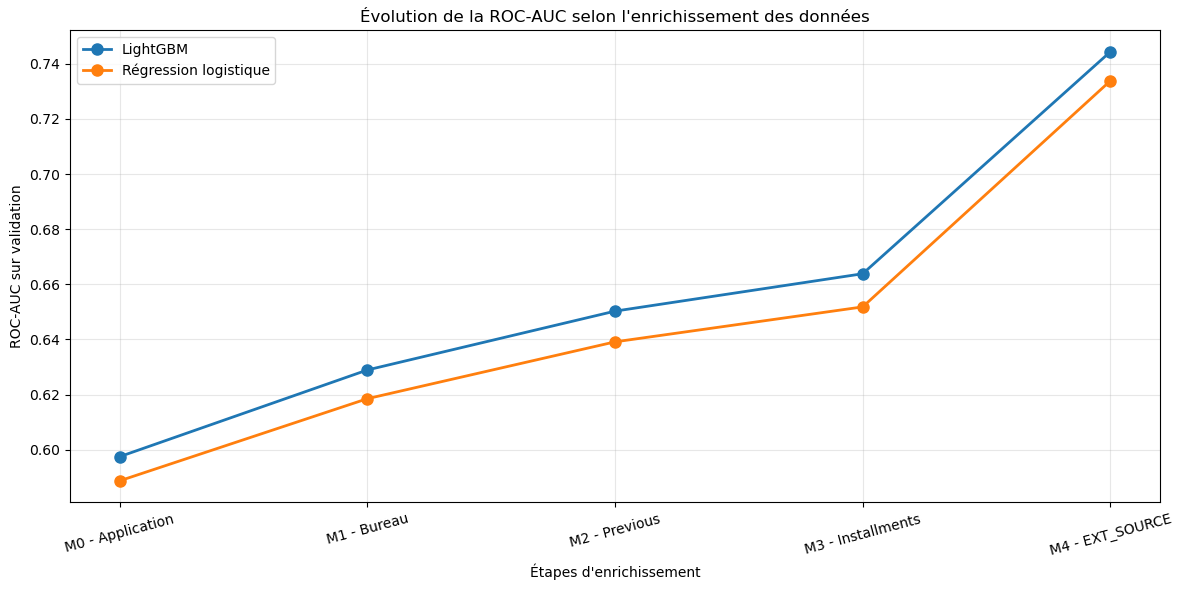

In [45]:
# =========================================================
# ÉVOLUTION DE LA ROC-AUC : M0 À M4
# =========================================================

ordre_etapes = [
    "M0 - Application",
    "M1 - Bureau",
    "M2 - Previous",
    "M3 - Installments",
    "M4 - EXT_SOURCE"
]

# Choix de la métrique représentée
metrique = "ROC-AUC validation"

# Organisation du tableau
progression_auc = comparaison_progressive.pivot(
    index="Étape",
    columns="Modèle",
    values=metrique
)

# Respect de l'ordre des enrichissements
progression_auc = progression_auc.reindex(
    ordre_etapes
)

# Vérification
assert progression_auc.notna().all().all(), (
    "Certaines étapes ou certains modèles sont manquants."
)

# =========================================================
# VISUALISATION
# =========================================================

plt.figure(figsize=(12, 6))

for modele in progression_auc.columns:

    plt.plot(
        progression_auc.index,
        progression_auc[modele],
        marker="o",
        markersize=8,
        linewidth=2,
        label=modele
    )

plt.title(
    "Évolution de la ROC-AUC selon l'enrichissement des données"
)

plt.xlabel("Étapes d'enrichissement")
plt.ylabel("ROC-AUC sur validation")

plt.xticks(rotation=15)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

,Variable,Gain,Importance (%)
19,EXT_SOURCE_3,48594.66,33.50
18,EXT_SOURCE_2,39504.83,27.23
17,EXT_SOURCE_1,16753.65,11.55
0,AGE,8551.12,5.89
15,LATE_PAYMENT_RATIO,5963.86,4.11
2,DTI_approx,4136.18,2.85
11,AVG_AMT_APPLICATION,3945.93,2.72
10,NB_REFUSED,3625.04,2.50
5,BUREAU_NB_CLOSED,3102.90,2.14
14,AVG_DELAY,2770.00,1.91


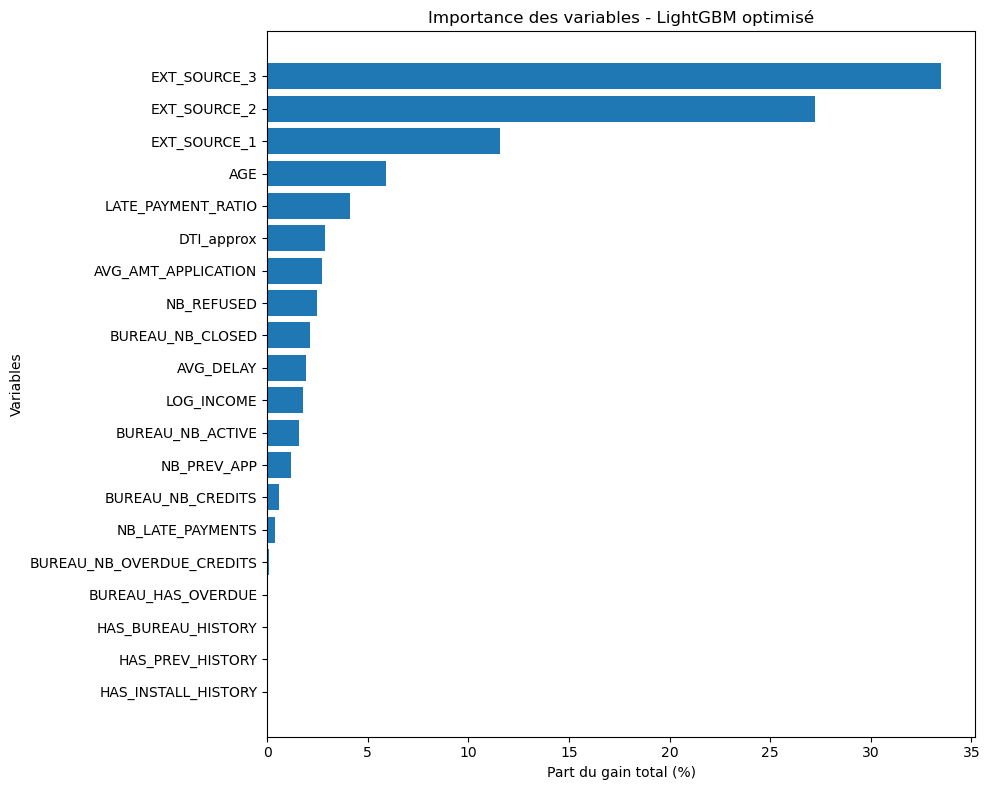

In [46]:
# =========================================================
# INTERPRÉTATION DU LIGHTGBM FINAL
# =========================================================

# Importance selon le gain
gains = modele_lgbm_ext.booster_.feature_importance(
    importance_type="gain"
)

importance = pd.DataFrame({
    "Variable": variables_ext,
    "Gain": gains
})

# Importance relative
importance["Importance (%)"] = (
    100 * importance["Gain"]
    / importance["Gain"].sum()
)

importance = importance.sort_values(
    "Importance (%)",
    ascending=False
)

display(importance.round(2))

# Graphique
plt.figure(figsize=(10, 8))

plt.barh(
    importance["Variable"],
    importance["Importance (%)"]
)

plt.gca().invert_yaxis()

plt.title(
    "Importance des variables - LightGBM optimisé"
)

plt.xlabel("Part du gain total (%)")
plt.ylabel("Variables")

plt.tight_layout()
plt.show()

In [48]:
# =========================================================
# ÉVALUATION APPROFONDIE DES MODÈLES FINAUX
# =========================================================

# ---------------------------------------------------------
# 1. Probabilités prédites
# ---------------------------------------------------------

y_eval = y_val_ext.to_numpy()

# Régression logistique optimisée
proba_lr = grid_lr_ext.predict_proba(
    X_val_ext
)[:, 1]

# LightGBM optimisé
proba_lgbm = random_lgbm_ext.predict_proba(
    X_val_ext
)[:, 1]


# ---------------------------------------------------------
# 2. Fonction d'évaluation du Top 10 %
# ---------------------------------------------------------

def evaluer_top10(y_true, proba):

    y_true = np.asarray(y_true)
    proba = np.asarray(proba)

    # Nombre de clients parmi les 10 % les plus risqués
    n_top = int(np.ceil(0.10 * len(y_true)))

    # Classement des clients par risque décroissant
    indices_top = np.argsort(-proba)[:n_top]

    # Taux de défaut dans le Top 10 %
    taux_top10 = y_true[indices_top].mean()

    # Proportion totale des défauts capturés
    capture_top10 = (
        y_true[indices_top].sum()
        / y_true.sum()
    )

    # Lift
    lift_top10 = (
        taux_top10 / y_true.mean()
    )

    return taux_top10, capture_top10, lift_top10


# ---------------------------------------------------------
# 3. Fonction de calcul du Brier Score
# ---------------------------------------------------------

def calculer_brier(y_true, proba):

    y_true = np.asarray(y_true)
    proba = np.asarray(proba)

    return np.mean((y_true - proba) ** 2)


# ---------------------------------------------------------
# 4. Comparaison des modèles
# ---------------------------------------------------------

resultats_evaluation = []

for nom, proba in [
    ("Régression logistique", proba_lr),
    ("LightGBM", proba_lgbm)
]:

    taux_top10, capture_top10, lift_top10 = evaluer_top10(
        y_eval,
        proba
    )

    resultats_evaluation.append({

        "Modèle": nom,

        "ROC-AUC": roc_auc_score(
            y_eval, proba
        ),

        "Average Precision": average_precision_score(
            y_eval, proba
        ),

        "Taux défaut Top 10 (%)": taux_top10 * 100,

        "Capture@10 (%)": capture_top10 * 100,

        "Lift@10": lift_top10,

        "Brier Score": calculer_brier(
            y_eval, proba
        )
    })


# Tableau final
evaluation_finale = pd.DataFrame(
    resultats_evaluation
)

print("=== ÉVALUATION DES MODÈLES FINAUX ===")

display(evaluation_finale.round(4))

=== ÉVALUATION DES MODÈLES FINAUX ===


,Modèle,ROC-AUC,Average Precision,Taux défaut Top 10 (%),Capture@10 (%),Lift@10,Brier Score
0,Régression logistique,0.7338,0.2083,24.4351,30.2719,3.0268,0.2086
1,LightGBM,0.7443,0.2257,25.9633,32.1652,3.2161,0.0686


In [49]:
# =========================================================
# ANALYSE DU RISQUE PAR DÉCILE - LIGHTGBM
# =========================================================

# Création d'un dataframe d'évaluation
df_deciles = pd.DataFrame({
    "TARGET": y_eval,
    "Score": proba_lgbm
})

# Classement du plus risqué au moins risqué
df_deciles = (
    df_deciles
    .sort_values(
        "Score",
        ascending=False,
        kind="stable"
    )
    .reset_index(drop=True)
)

# Attribution des déciles
# Décile 1 = 10 % des clients les plus risqués
df_deciles["Décile"] = (
    np.arange(len(df_deciles)) * 10
    // len(df_deciles)
) + 1


# Calcul des indicateurs par décile
table_deciles = (
    df_deciles
    .groupby("Décile")
    .agg(
        Nombre_clients=("TARGET", "size"),
        Nombre_defauts=("TARGET", "sum"),
        Taux_defaut=("TARGET", "mean"),
        Score_moyen=("Score", "mean")
    )
)


# Taux de défaut en pourcentage
table_deciles["Taux_defaut_pct"] = (
    table_deciles["Taux_defaut"] * 100
)

# Lift par décile
table_deciles["Lift"] = (
    table_deciles["Taux_defaut"]
    / y_eval.mean()
)

# Proportion cumulée des défauts capturés
table_deciles["Capture_cumulee_pct"] = (
    table_deciles["Nombre_defauts"].cumsum()
    / table_deciles["Nombre_defauts"].sum()
    * 100
)


# Affichage
display(
    table_deciles[
        [
            "Nombre_clients",
            "Nombre_defauts",
            "Score_moyen",
            "Taux_defaut_pct",
            "Lift",
            "Capture_cumulee_pct"
        ]
    ].round(3)
)

,Nombre_clients,Nombre_defauts,Score_moyen,Taux_defaut_pct,Lift,Capture_cumulee_pct
Décile,,,,,,
1,6151,1597,0.264,25.963,3.216,32.165
2,6150,892,0.147,14.504,1.797,50.131
3,6150,617,0.103,10.033,1.243,62.558
4,6150,509,0.078,8.276,1.025,72.810
5,6150,384,0.061,6.244,0.773,80.544
6,6151,312,0.048,5.072,0.628,86.828
7,6150,230,0.039,3.740,0.463,91.460
8,6150,192,0.031,3.122,0.387,95.327
9,6150,142,0.024,2.309,0.286,98.187


In [53]:
# =========================================================
# INTERPRÉTATION DES DÉCILES DE RISQUE
# =========================================================

# Bornes des scores prédits par décile
bornes_deciles = (
    df_deciles
    .groupby("Décile")
    .agg(
        Score_min=("Score", "min"),
        Score_max=("Score", "max")
    )
)

# Ajout au tableau existant
table_deciles = table_deciles.join(
    bornes_deciles
)

# Affichage en pourcentage
table_deciles["Score_min_pct"] = (
    table_deciles["Score_min"] * 100
)

table_deciles["Score_max_pct"] = (
    table_deciles["Score_max"] * 100
)

display(
    table_deciles[
        [
            "Nombre_clients",
            "Score_min_pct",
            "Score_max_pct",
            "Taux_defaut_pct",
            "Lift",
            "Capture_cumulee_pct"
        ]
    ].round(2)
)

,Nombre_clients,Score_min_pct,Score_max_pct,Taux_defaut_pct,Lift,Capture_cumulee_pct
Décile,,,,,,
1,6151,17.99,75.89,25.96,3.22,32.17
2,6150,12.05,17.98,14.50,1.80,50.13
3,6150,8.85,12.05,10.03,1.24,62.56
4,6150,6.84,8.85,8.28,1.03,72.81
5,6150,5.38,6.84,6.24,0.77,80.54
6,6151,4.31,5.38,5.07,0.63,86.83
7,6150,3.44,4.31,3.74,0.46,91.46
8,6150,2.71,3.44,3.12,0.39,95.33
9,6150,2.01,2.71,2.31,0.29,98.19


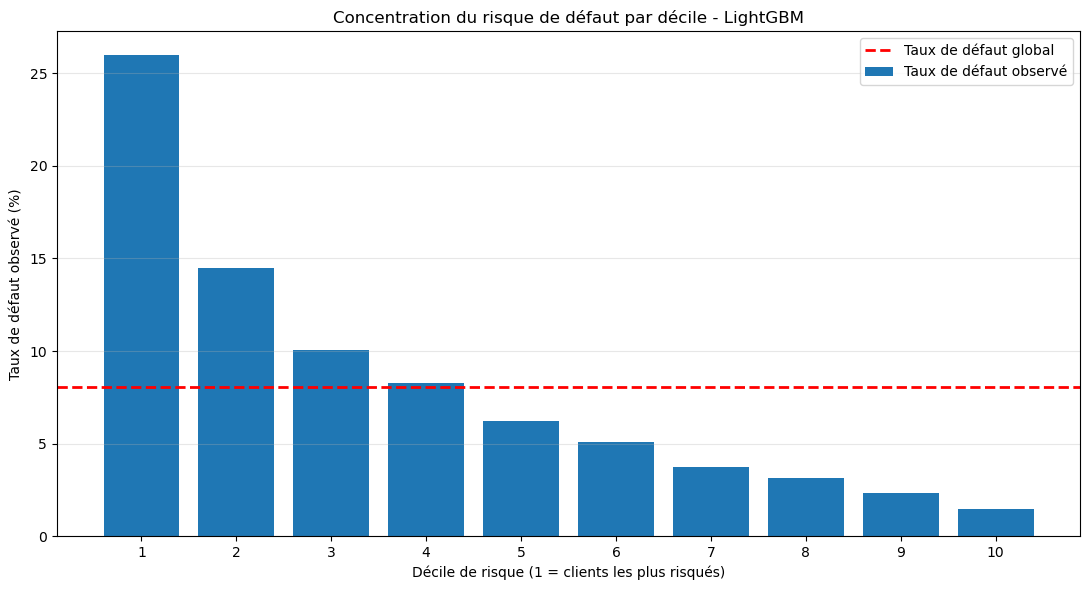

In [50]:
# =========================================================
# TAUX DE DÉFAUT OBSERVÉ PAR DÉCILE
# =========================================================

plt.figure(figsize=(11, 6))

# Taux de défaut par décile
plt.bar(
    table_deciles.index,
    table_deciles["Taux_defaut_pct"],
    label="Taux de défaut observé"
)

# Taux de défaut global
plt.axhline(
    y=y_eval.mean() * 100,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Taux de défaut global"
)

plt.title(
    "Concentration du risque de défaut par décile - LightGBM"
)

plt.xlabel(
    "Décile de risque (1 = clients les plus risqués)"
)

plt.ylabel("Taux de défaut observé (%)")

plt.xticks(range(1, 11))

plt.legend()

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

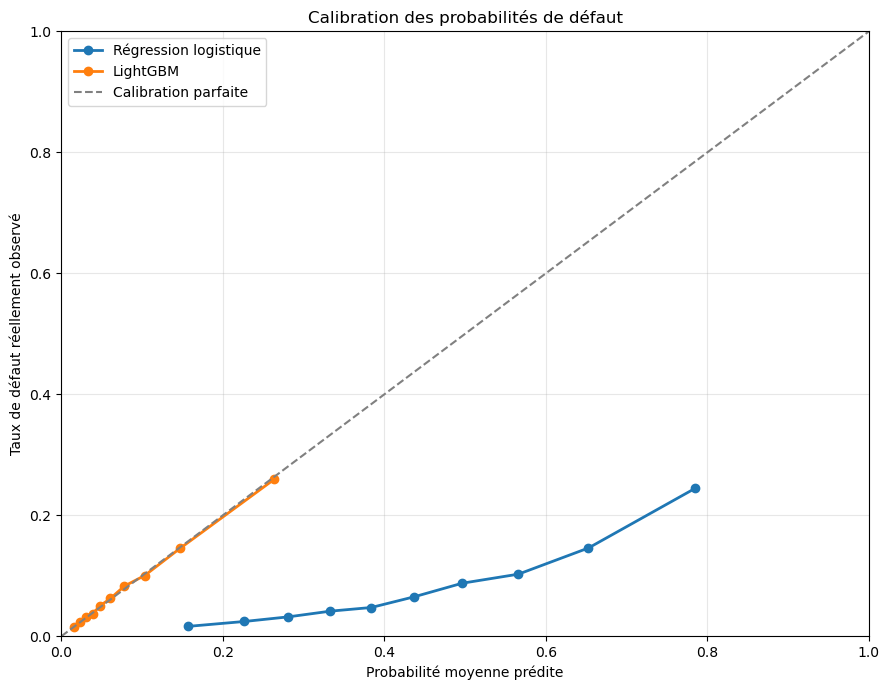

In [51]:
# =========================================================
# CALIBRATION DES PROBABILITÉS
# =========================================================

from sklearn.calibration import calibration_curve

plt.figure(figsize=(9, 7))

# Comparaison des deux algorithmes
for nom, proba in [
    ("Régression logistique", proba_lr),
    ("LightGBM", proba_lgbm)
]:

    fraction_positives, proba_moyenne = calibration_curve(
        y_eval,
        proba,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        proba_moyenne,
        fraction_positives,
        marker="o",
        linewidth=2,
        label=nom
    )


# Diagonale de calibration parfaite
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Calibration parfaite"
)

plt.title(
    "Calibration des probabilités de défaut"
)

plt.xlabel(
    "Probabilité moyenne prédite"
)

plt.ylabel(
    "Taux de défaut réellement observé"
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()